# Proyecto Final (Parte 2): Descubriendo perfiles de árboles con Aprendizaje No Supervisado

### Censo de Árboles Callejeros 2015 - NYC Parks

En la **Parte 1** (`Final.ipynb`) le enseñamos a un modelo a **predecir** si la vereda de un árbol estaba dañada, usando la columna `sidewalk` como "respuesta correcta". En esta **Parte 2** hacemos algo distinto: **apartamos esa respuesta** y le preguntamos a los datos si, por sí solos, los árboles se ordenan en grupos o patrones naturales.

Es el mismo censo y el mismo trabajo previo de limpieza, pero la pregunta cambia por completo.

---

### ¿En qué se diferencia de la Parte 1 (`Final.ipynb`)?

| Aspecto | Parte 1: Supervisado (`Final.ipynb`) | Parte 2: No supervisado (este notebook) |
|---|---|---|
| **Pregunta** | ¿Esta vereda está dañada? | ¿Qué tipos de árboles existen y qué patrones hay entre ellos? |
| **Uso de `sidewalk`** | Es el *target*: el modelo aprende de él | **No se usa para agrupar**. Solo se reincorpora al final para comparar |
| **Técnicas** | Dummy, Regresión Logística, Árbol de Decisión, Random Forest | K-Means, PCA y DBSCAN |
| **Partición Train / Test** | Sí (80/20 estratificada), para medir si generaliza | **No**: no hay nada que predecir ni una respuesta contra la cual testear |
| **Preprocesamiento** | `StandardScaler` + One-Hot, dentro de un `Pipeline` | `RobustScaler` (por los atípicos) y solo variables físicas del árbol |
| **Cómo sabemos si anduvo bien** | Métricas contra la realidad: F1, Recall, ROC-AUC | Métricas internas: codo, Silhouette, varianza explicada, k-distancias |
| **Resultado** | Un clasificador (F1 ≈ 0,54) | Perfiles de árboles y componentes principales |
| **Interpretación** | Importancia por permutación y dependencia parcial | Perfil de cada grupo en escalas y unidades originales |

> **La idea clave:** en el supervisado hay una respuesta correcta y podemos medir cuánto nos acercamos. En el no supervisado **no la hay**: el algoritmo propone una estructura y nosotros tenemos que decidir si tiene sentido. Por eso la interpretación y la justificación de cada decisión pesan tanto más.

---

### Objetivo
Descubrir, **sin usar etiquetas**, si los árboles del censo se agrupan en perfiles diferenciables y qué ejes concentran la variación de los datos. Para eso vamos a:
1. Preparar una matriz de trabajo con escalado robusto a atípicos.
2. Aplicar **K-Means** (eligiendo *K* con el método del codo y el Silhouette).
3. Aplicar **PCA** (analizando la varianza acumulada y los *loadings*).
4. Probar **DBSCAN** (determinando *ε* con las k-distancias) y ver si segmenta o si conviene usarlo como detector de anomalías.
5. Describir cada grupo en lenguaje de dominio y **contrastarlo al final con `sidewalk`**.


## 1. Carga y limpieza (reutilizando la Parte 1)

### Objetivo:
No tiene sentido repetir el análisis exploratorio completo: ya lo hicimos en `Final.ipynb`. Acá **reutilizamos exactamente el mismo filtrado y limpieza**, para que los dos trabajos hablen del mismo conjunto de árboles:
- Solo árboles vivos con el estado de la vereda registrado.
- Los nulos de `steward` significan "sin vecino cuidador", así que se completan con `'None'`.
- Diámetros entre 1 y 60 pulgadas (se descartan los valores imposibles).
- Los mismos puntajes de conflicto (0 a 3) para raíces, tronco y ramas.

Para ahorrar memoria leemos solo las columnas necesarias. Ojo: en este paso **no creamos el `target`**, porque no lo vamos a usar para agrupar.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OrdinalEncoder, OneHotEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

RANDOM_STATE = 42

In [2]:
# Carga solo de las columnas necesarias (el CSV completo pesa ~280 MB)
cols = ['status', 'sidewalk', 'tree_dbh', 'steward', 'health', 'borough', 'curb_loc',
        'root_stone', 'root_grate', 'root_other',
        'trunk_wire', 'trnk_light', 'trnk_other',
        'brch_light', 'brch_shoe', 'brch_other']
df_raw = pd.read_csv('2015_Street_Tree_Census_-_Tree_Data_20260914.csv', usecols=cols)
print(f"Dataset original: {df_raw.shape[0]:,} filas")

# Mismo filtrado y limpieza del proyecto supervisado (Final.ipynb)
df = df_raw[(df_raw['status'] == 'Alive') & (df_raw['sidewalk'].notnull())].copy()
df['steward'] = df['steward'].fillna('None')
df_clean = df[(df['tree_dbh'] > 0) & (df['tree_dbh'] <= 60)].copy()

# Feature engineering: puntajes de conflicto (0 a 3), igual que en Final.ipynb
df_clean['root_conflict_score'] = (df_clean[['root_stone', 'root_grate', 'root_other']] == 'Yes').sum(axis=1)
df_clean['trunk_conflict_score'] = (df_clean[['trunk_wire', 'trnk_light', 'trnk_other']] == 'Yes').sum(axis=1)
df_clean['branch_conflict_score'] = (df_clean[['brch_light', 'brch_shoe', 'brch_other']] == 'Yes').sum(axis=1)

df_clean = df_clean.dropna(subset=['health'])
print(f"Árboles vivos con vereda conocida y diámetro válido (1 a 60 pulg): {len(df_clean):,}")

Dataset original: 683,788 filas


Árboles vivos con vereda conocida y diámetro válido (1 a 60 pulg): 651,799


### Conclusiones:

1. **Mismo universo que la Parte 1:** quedan **651.799 árboles** vivos con vereda conocida y diámetro válido. Es prácticamente el mismo conjunto que usamos para el modelo supervisado.
2. **La limpieza ya hace una primera parte del trabajo con los atípicos:** al descartar los diámetros de 0 y los mayores a 60 pulgadas sacamos los valores imposibles. Más adelante vamos a ver qué pasa con los atípicos "reales" que sí quedaron.

---

## 2. Matriz de trabajo: qué variables entran y cuáles no

### Objetivo:
Armar la matriz `X` con la que se agrupa. Hay tres decisiones importantes:

1. **Sin etiqueta:** `sidewalk` queda guardada en `y_externa`, pero **no entra en `X`**. Solo la usaremos al final como validación externa.
2. **Submuestra de 20.000 árboles:** K-Means y sobre todo el Silhouette y DBSCAN calculan distancias entre muchos puntos y se vuelven muy lentos con 650.000 filas. Con 20.000 la estructura se conserva y todo corre en segundos. Es una muestra aleatoria simple (no estratificada, porque no hay clases que equilibrar).
3. **Solo variables físicas del árbol:** diámetro, los tres puntajes de conflicto, `steward` y `health`. Dejamos `borough` y `curb_loc` **fuera del agrupamiento** y las guardamos aparte (`contexto`) para usarlas solo al interpretar.

¿Por qué sacamos `borough`? En una primera prueba la incluimos con One-Hot y los grupos resultantes se armaron casi **por barrio** (un cluster era 100% Queens, otro 100% Brooklyn) y el Silhouette para K=4 era peor (0,21). Es un efecto conocido: las columnas 0/1 pesan mucho en las distancias y terminan dominando. Como lo que queremos descubrir son **tipos de árboles** y no una división geográfica, preferimos que el barrio sea una variable para describir los grupos y no para formarlos.

Antes de escalar, además, revisamos los atípicos del diámetro con la regla del rango intercuartil (IQR).


In [3]:
features_num = ['tree_dbh', 'root_conflict_score', 'trunk_conflict_score', 'branch_conflict_score']
features_ord = ['steward', 'health']
features_ctx = ['borough', 'curb_loc']   # contexto: NO entran al clustering, se usan solo para interpretar

# Submuestra aleatoria (sin estratificar: no hay etiqueta que preservar)
df_sample = df_clean.sample(n=20000, random_state=RANDOM_STATE)

# Matriz de trabajo: SOLO predictoras. La etiqueta queda guardada aparte y NO se usa para agrupar.
X = df_sample[features_num + features_ord].reset_index(drop=True)
contexto = df_sample[features_ctx].reset_index(drop=True)
y_externa = (df_sample['sidewalk'] == 'Damage').astype(int).reset_index(drop=True)

print("Matriz X para el clustering:", X.shape)
print("Columnas:", list(X.columns))
display(X.head())
display(X[features_num].describe().T)

Matriz X para el clustering: (20000, 6)
Columnas: ['tree_dbh', 'root_conflict_score', 'trunk_conflict_score', 'branch_conflict_score', 'steward', 'health']


,tree_dbh,root_conflict_score,trunk_conflict_score,branch_conflict_score,steward,health
0,10,0,0,0,3or4,Fair
1,32,1,0,1,None,Good
2,7,0,0,0,None,Good
3,6,0,0,0,None,Fair
4,4,1,0,0,None,Good


,count,mean,std,min,25%,50%,75%,max
tree_dbh,20000.00,11.64,8.38,1.00,5.00,10.00,16.00,57.00
root_conflict_score,20000.00,0.27,0.48,0.00,0.00,0.00,0.00,3.00
trunk_conflict_score,20000.00,0.07,0.27,0.00,0.00,0.00,0.00,2.00
branch_conflict_score,20000.00,0.14,0.35,0.00,0.00,0.00,0.00,2.00


Límite superior IQR del diámetro: 32.5 pulgadas
Árboles por encima de ese límite: 481 (2.4%)


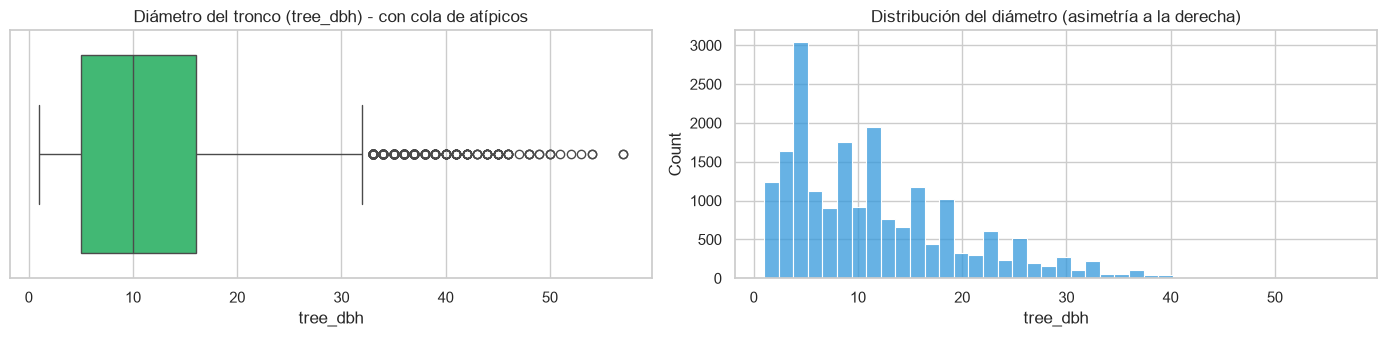

In [4]:
# Diagnóstico de atípicos con la regla del rango intercuartil (IQR) para el diámetro
q1, q3 = X['tree_dbh'].quantile([0.25, 0.75])
lim_sup = q3 + 1.5 * (q3 - q1)
n_out = (X['tree_dbh'] > lim_sup).sum()
print(f"Límite superior IQR del diámetro: {lim_sup:.1f} pulgadas")
print(f"Árboles por encima de ese límite: {n_out:,} ({n_out / len(X) * 100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
sns.boxplot(x=X['tree_dbh'], color='#2ecc71', ax=axes[0])
axes[0].set_title('Diámetro del tronco (tree_dbh) - con cola de atípicos')
sns.histplot(X['tree_dbh'], bins=40, color='#3498db', ax=axes[1])
axes[1].set_title('Distribución del diámetro (asimetría a la derecha)')
plt.tight_layout()
plt.show()

### Conclusiones:

1. **Matriz final de 20.000 árboles × 6 variables:** 4 numéricas (`tree_dbh` y los tres puntajes de conflicto) y 2 ordinales (`steward`, `health`).
2. **El diámetro tiene una cola larga a la derecha:** la mediana es de 10 pulgadas, pero el promedio es 11,6 y el desvío 8,4. Según la regla del IQR, todo lo que supera las **32,5 pulgadas** es atípico: son **481 árboles (2,4%)**.
3. **¿Los eliminamos?** No. Son árboles grandes reales (hasta 57 pulgadas), no errores de carga: justamente los más interesantes para la pregunta del proyecto. En lugar de borrarlos, vamos a usar un escalador que no se deje arrastrar por ellos (`RobustScaler`).

---

## 3. Preprocesamiento: escalado robusto y codificación

### Objetivo:
K-Means, DBSCAN y PCA se basan en **distancias**. Si una variable tiene valores grandes (como el diámetro, de 1 a 57) y otra va de 0 a 3, la primera dominaría todo. Por eso hay que llevar las variables a una escala comparable.

- **`RobustScaler`** en lugar de `StandardScaler`: en vez de usar el promedio y el desvío, usa la **mediana y el rango intercuartil**. Así los atípicos del diámetro no distorsionan la escala de los demás.
- **`OrdinalEncoder`** para `steward` (`None < 1or2 < 3or4 < 4orMore`) y `health` (`Poor < Fair < Good`), respetando el orden natural, y luego se escalan igual que las numéricas.
- **No hace falta One-Hot:** como `borough` y `curb_loc` quedaron fuera, las seis variables son numéricas u ordinales.

Todo se arma en un `ColumnTransformer`, igual que en la Parte 1. La diferencia es que acá **ajustamos con todos los datos de la muestra**: como no existe un set de test ni nadie evalúa predicciones, el problema de fuga de información (*data leakage*) de la Parte 1 no aplica de la misma manera.


In [5]:
steward_cats = ['None', '1or2', '3or4', '4orMore']
health_cats = ['Poor', 'Fair', 'Good']

# RobustScaler (mediana e IQR) para variables numéricas y ordinales: resiste a los atípicos de tree_dbh.
# borough y curb_loc quedan fuera del clustering (ver Markdown): se usan solo para describir los grupos.
preprocessor_cluster = ColumnTransformer(transformers=[
    ('num', RobustScaler(), features_num),
    ('ord', Pipeline([
        ('enc', OrdinalEncoder(categories=[steward_cats, health_cats])),
        ('sc', RobustScaler())
    ]), features_ord)
])

X_scaled = preprocessor_cluster.fit_transform(X)
feature_names = [n.split('__')[1] for n in preprocessor_cluster.get_feature_names_out()]
print("Forma de la matriz escalada:", X_scaled.shape)
display(pd.DataFrame(X_scaled, columns=feature_names).describe().T[['mean', 'std', 'min', 'max']])

Forma de la matriz escalada: (20000, 6)


,mean,std,min,max
tree_dbh,0.15,0.76,-0.82,4.27
root_conflict_score,0.27,0.48,0.00,3.00
trunk_conflict_score,0.07,0.27,0.00,2.00
branch_conflict_score,0.14,0.35,0.00,2.00
steward,0.29,0.53,0.00,3.00
health,-0.23,0.51,-2.00,0.00


### Conclusiones:

1. **Matriz escalada de 20.000 × 6**, lista para los tres algoritmos.
2. **El diámetro quedó centrado en la mediana** (promedio 0,15, desvío 0,76) y sus atípicos siguen siendo visibles (máximo 4,27) pero comprimidos, sin aplastar al resto.
3. **Los puntajes de conflicto conservan su escala de 0 a 3.** Como más del 75% de los árboles tiene valor 0, su IQR es 0 y el `RobustScaler` los deja con escala 1. Es un comportamiento esperable y no un error.
4. **Todas las variables quedan en rangos comparables** (aproximadamente entre -2 y 4), así que ninguna manda por tener "números más grandes".

---

## 4. K-Means: ¿cuántos grupos hay?

### Objetivo:
**K-Means** reparte los árboles en *K* grupos buscando que cada uno quede lo más compacto posible alrededor de su centro. El problema es que **hay que decirle cuántos grupos queremos**. Para elegir *K* de forma justificada usamos dos criterios complementarios:

- **Método del codo (inercia):** la inercia mide qué tan dispersos están los puntos dentro de sus grupos y siempre baja al aumentar *K*. Buscamos el punto donde la mejora empieza a ser marginal.
- **Coeficiente de Silhouette:** va de -1 a 1 y mide qué tan bien separado está cada árbol de los grupos vecinos. Valores cercanos a 1 indican grupos bien definidos; cercanos a 0, grupos que se pisan.

Probamos *K* de 2 a 10 (con `n_init=10` para no depender de una inicialización con suerte). Como el Silhouette compara todos los pares de puntos, se calcula sobre una submuestra de 5.000 árboles.


,K,Inercia,Silhouette
0,2,22320.31,0.32
1,3,18211.78,0.31
2,4,14966.68,0.33
3,5,13004.10,0.35
4,6,11718.11,0.34
5,7,10955.74,0.35
6,8,10255.04,0.35
7,9,9611.68,0.36
8,10,9078.70,0.39


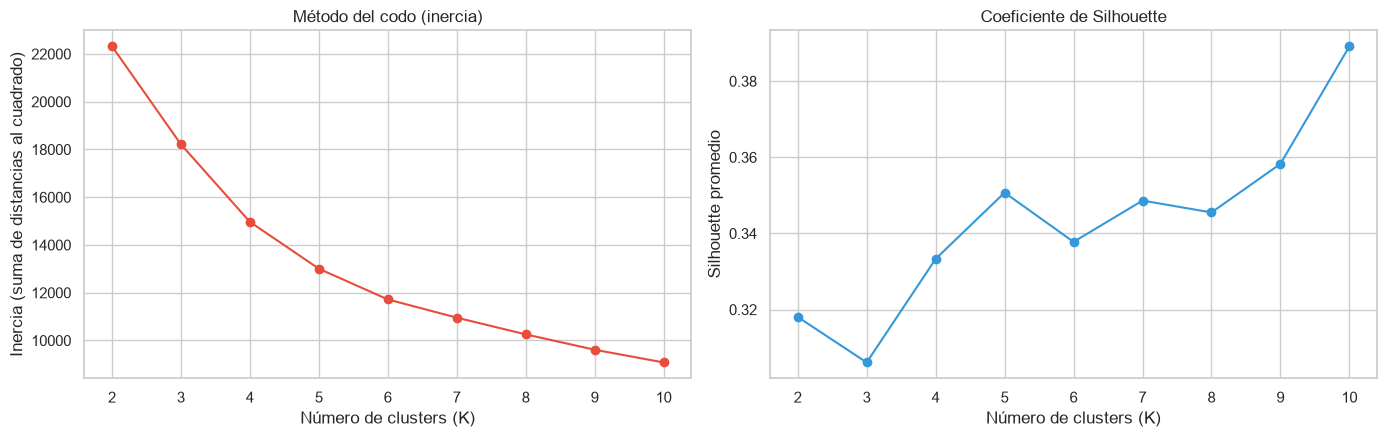

In [6]:
k_range = range(2, 11)
inercias, siluetas = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_scaled, km.labels_, sample_size=5000, random_state=RANDOM_STATE))

res_k = pd.DataFrame({'K': list(k_range), 'Inercia': inercias, 'Silhouette': siluetas})
display(res_k.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(res_k['K'], res_k['Inercia'], 'o-', color='#e74c3c')
axes[0].set_title('Método del codo (inercia)')
axes[0].set_xlabel('Número de clusters (K)')
axes[0].set_ylabel('Inercia (suma de distancias al cuadrado)')
axes[1].plot(res_k['K'], res_k['Silhouette'], 'o-', color='#3498db')
axes[1].set_title('Coeficiente de Silhouette')
axes[1].set_xlabel('Número de clusters (K)')
axes[1].set_ylabel('Silhouette promedio')
plt.tight_layout()
plt.show()

### Conclusiones (elección de K):

1. **El codo aparece alrededor de K = 4 a 5:** la inercia baja mucho al pasar de 2 a 3 grupos (22.320 → 18.212) y de 3 a 4 (→ 14.967), y después las mejoras se achican de forma sostenida (→ 13.004, → 11.718).
2. **El Silhouette no marca un máximo claro:** vale 0,32 para K=2, 0,33 para K=4, 0,35 para K=5 y sigue subiendo lentamente hasta 0,39 para K=10. Eso no significa que haya 10 grupos reales: como las variables son discretas (pocos valores posibles), K-Means puede seguir partiendo en trozos cada vez más chicos sin que aparezca una estructura nueva.
3. **Elegimos K = 4:** ahí empieza el codo, el Silhouette (0,33) es razonable y, sobre todo, los grupos se pueden **describir y explicar** (se ve en la sección siguiente). Con más grupos los perfiles empiezan a parecerse entre sí y se vuelven difíciles de interpretar.

*Esta es una decisión de criterio y no una verdad matemática: ningún método nos da el "K correcto" y hay que justificarlo con lo que tiene sentido para el problema.*


K elegido: 4 | Silhouette (muestra de 5000): 0.3333

Tamaño de cada cluster:


,Cantidad,Porcentaje
0,8400,42.00
1,4587,22.93
2,3798,18.99
3,3215,16.07


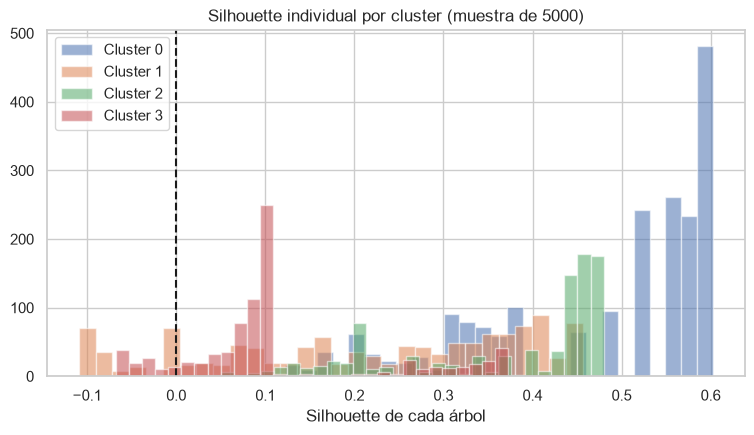

In [7]:
K_ELEGIDO = 4

kmeans = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
labels_km = kmeans.labels_
print(f"K elegido: {K_ELEGIDO} | Silhouette (muestra de 5000): "
      f"{silhouette_score(X_scaled, labels_km, sample_size=5000, random_state=RANDOM_STATE):.4f}")
print("\nTamaño de cada cluster:")
display(pd.Series(labels_km).value_counts().sort_index().rename('Cantidad').to_frame().assign(
    Porcentaje=lambda d: d['Cantidad'] / len(labels_km) * 100))

# Silhouette individual: ¿hay árboles mal asignados (valores negativos)?
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_scaled), 5000, replace=False)
sil_ind = silhouette_samples(X_scaled[idx], labels_km[idx])
plt.figure(figsize=(9, 4.5))
for c in range(K_ELEGIDO):
    plt.hist(sil_ind[labels_km[idx] == c], bins=30, alpha=0.55, label=f'Cluster {c}')
plt.axvline(0, color='k', linestyle='--')
plt.title('Silhouette individual por cluster (muestra de 5000)')
plt.xlabel('Silhouette de cada árbol')
plt.legend()
plt.show()

### Conclusiones (modelo final con K = 4):

1. **Cuatro grupos de buen tamaño:** 42%, 23%, 19% y 16% de los árboles. Ninguno es marginal.
2. **Estructura moderada:** el Silhouette de 0,33 indica que los grupos existen pero sus bordes son difusos. Es lo esperable en datos reales con variables ordinales: los árboles no se separan en "islas", sino que cambian gradualmente de un perfil a otro.

---

## 5. Interpretación: ¿qué tipo de árbol es cada grupo?

### Objetivo:
Un cluster sin explicación no sirve de nada. Para entenderlos, calculamos el **perfil de cada grupo en sus escalas y unidades originales** (pulgadas, puntajes de 0 a 3, porcentajes), no en las unidades escaladas del algoritmo. También miramos cómo se reparten los barrios dentro de cada grupo, aunque `borough` no participó en el agrupamiento.


In [8]:
perfil = pd.concat([X, contexto], axis=1)
perfil['cluster'] = labels_km
perfil['health_Good'] = (perfil['health'] == 'Good').astype(int) * 100
perfil['health_Poor'] = (perfil['health'] == 'Poor').astype(int) * 100
perfil['steward_None'] = (perfil['steward'] == 'None').astype(int) * 100
perfil['curb_OnCurb'] = (perfil['curb_loc'] == 'OnCurb').astype(int) * 100

resumen = perfil.groupby('cluster').agg(
    Arboles=('tree_dbh', 'size'),
    Diametro_prom_pulg=('tree_dbh', 'mean'),
    Diametro_mediana_pulg=('tree_dbh', 'median'),
    Conflicto_raiz=('root_conflict_score', 'mean'),
    Conflicto_tronco=('trunk_conflict_score', 'mean'),
    Conflicto_ramas=('branch_conflict_score', 'mean'),
    Pct_salud_Good=('health_Good', 'mean'),
    Pct_salud_Poor=('health_Poor', 'mean'),
    Pct_sin_steward=('steward_None', 'mean'),
    Pct_sobre_cordon=('curb_OnCurb', 'mean'),
)
resumen['Pct_del_total'] = resumen['Arboles'] / len(perfil) * 100
print("Perfil de cada cluster en escalas y unidades ORIGINALES:")
display(resumen.round(2))

print("\nDistribución por borough dentro de cada cluster (%):")
display((pd.crosstab(perfil['cluster'], perfil['borough'], normalize='index') * 100).round(1))

Perfil de cada cluster en escalas y unidades ORIGINALES:


,Arboles,Diametro_prom_pulg,Diametro_mediana_pulg,Conflicto_raiz,Conflicto_tronco,Conflicto_ramas,Pct_salud_Good,Pct_salud_Poor,Pct_sin_steward,Pct_sobre_cordon,Pct_del_total
cluster,,,,,,,,,,,
0,8400,8.17,8.00,0.16,0.04,0.09,100.00,0.00,100.00,96.63,42.00
1,4587,23.90,23.00,0.56,0.10,0.21,89.25,0.35,91.45,94.88,22.94
2,3798,7.16,6.00,0.14,0.07,0.10,97.45,0.03,0.00,96.00,18.99
3,3215,8.47,8.00,0.27,0.13,0.20,0.00,25.88,73.34,96.42,16.08



Distribución por borough dentro de cada cluster (%):


borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
cluster,,,,,
0,15.40,22.10,7.20,36.30,19.00
1,9.20,31.10,3.00,46.00,10.70
2,9.70,29.30,20.10,27.00,13.90
3,11.20,25.50,12.10,36.40,14.70


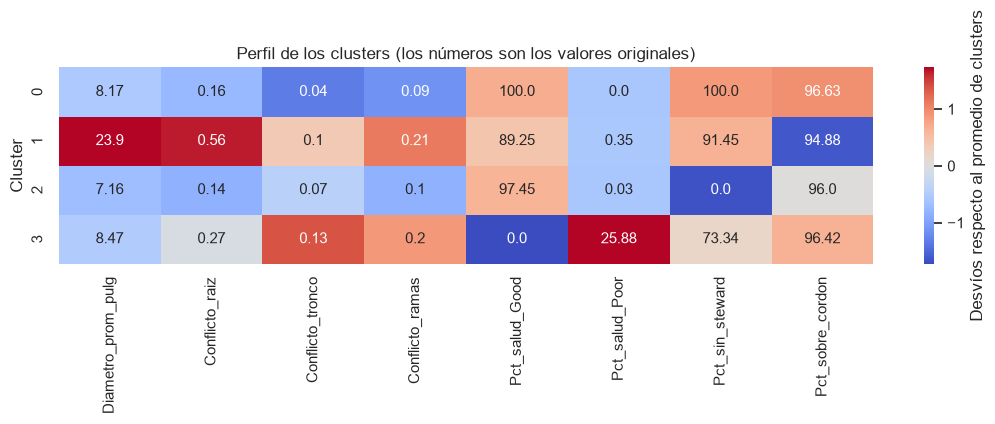

In [9]:
# Mapa de calor: cuánto se aleja cada cluster del promedio general (en desvíos estándar)
vars_heat = ['Diametro_prom_pulg', 'Conflicto_raiz', 'Conflicto_tronco', 'Conflicto_ramas',
             'Pct_salud_Good', 'Pct_salud_Poor', 'Pct_sin_steward', 'Pct_sobre_cordon']
z = (resumen[vars_heat] - resumen[vars_heat].mean()) / resumen[vars_heat].std(ddof=0).replace(0, 1)
plt.figure(figsize=(11, 4))
sns.heatmap(z, annot=resumen[vars_heat].round(2), fmt='', cmap='coolwarm', center=0, cbar_kws={'label': 'Desvíos respecto al promedio de clusters'})
plt.title('Perfil de los clusters (los números son los valores originales)')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()

### Conclusiones (perfiles de los clusters):

| Cluster | Etiqueta propuesta | % del total | Qué lo distingue |
|:---:|---|:---:|---|
| **0** | **Jóvenes, sanos y sin cuidado vecinal** | 42% | Diámetro de ~8 pulgadas, **100% con salud buena** y **100% sin vecino cuidador** (`steward = None`). Pocos conflictos (raíz 0,16). Es el árbol "típico" de la ciudad. |
| **1** | **Árboles grandes y maduros** | 23% | Diámetro de **~24 pulgadas** (3 veces el del resto). **Conflictos de raíz de 0,56**, más de 3 veces los de los grupos jóvenes, y también más conflictos de tronco (0,10) y ramas (0,21). Casi todos sin cuidador (91%). |
| **2** | **Jóvenes cuidados por vecinos** | 19% | Diámetro de ~7 pulgadas, el más chico. **0% sin cuidador:** todos tienen algún vecino que los cuida. 97% con buena salud. |
| **3** | **Árboles con mala salud** | 16% | **Ninguno tiene salud buena** (0%): 26% en estado malo y el resto regular. Además tienen más conflictos de tronco (0,13) y ramas (0,20) que los grupos jóvenes sanos. |

1. **Los grupos se separan por 3 ejes:** el **tamaño** (grupo 1), el **cuidado vecinal** (grupos 0 vs 2) y la **salud** (grupo 3). Tiene sentido de dominio: son justo las dimensiones que describen la "vida" de un árbol urbano.
2. **El barrio casi no define los grupos:** la distribución por borough es parecida entre clusters. La excepción es Manhattan, que pesa el 20% en el grupo de árboles cuidados frente al 7% en el grupo 0, algo consistente con un mayor nivel de cuidado vecinal en esa zona. Esto confirma que sacar `borough` del agrupamiento fue una buena decisión: los perfiles reflejan características del árbol y no la geografía.

---

## 6. PCA: ¿cuántas dimensiones necesitamos realmente?

### Objetivo:
**PCA** es otra técnica no supervisada, pero con un propósito distinto: no arma grupos, sino que **reduce la cantidad de variables** combinándolas en nuevos ejes llamados *componentes principales*, ordenados de mayor a menor varianza explicada. Analizamos:

- **La varianza explicada acumulada (scree plot):** cuántos componentes necesitamos para conservar, por ejemplo, el 80% de la información.
- **Los *loadings*:** cuánto pesa cada variable original en cada componente, para poder ponerle nombre a los ejes.
- **Una proyección en 2D** coloreada con los clusters de K-Means, solo como apoyo visual (si los dos primeros componentes no alcanzan, no hay que sobreinterpretarla).


Componentes totales: 6
Componentes para alcanzar el 80% de varianza: 4
Componentes para alcanzar el 90% de varianza: 5
Varianza explicada por PC1 + PC2: 58.8%


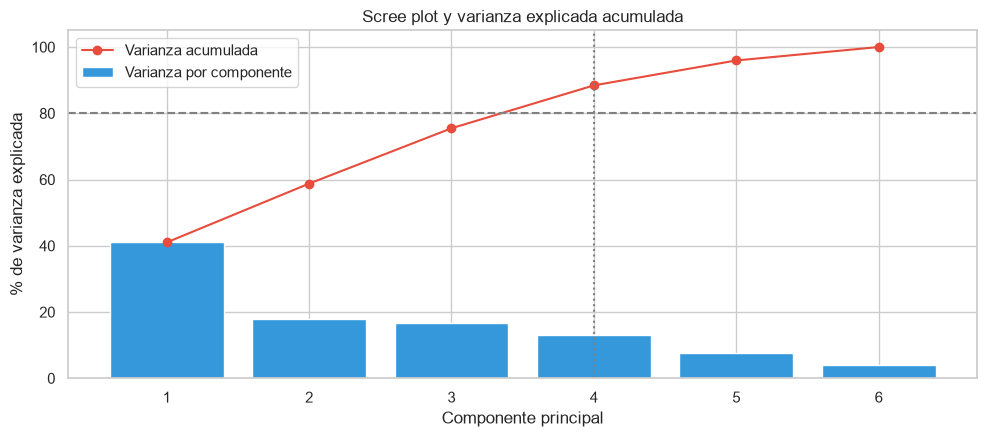

In [10]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
var_exp = pca_full.explained_variance_ratio_
var_acum = np.cumsum(var_exp)
n_80 = int(np.argmax(var_acum >= 0.80) + 1)
n_90 = int(np.argmax(var_acum >= 0.90) + 1)

print(f"Componentes totales: {len(var_exp)}")
print(f"Componentes para alcanzar el 80% de varianza: {n_80}")
print(f"Componentes para alcanzar el 90% de varianza: {n_90}")
print(f"Varianza explicada por PC1 + PC2: {var_acum[1] * 100:.1f}%")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(1, len(var_exp) + 1), var_exp * 100, color='#3498db', label='Varianza por componente')
ax.plot(range(1, len(var_exp) + 1), var_acum * 100, 'o-', color='#e74c3c', label='Varianza acumulada')
ax.axhline(80, color='gray', linestyle='--')
ax.axvline(n_80, color='gray', linestyle=':')
ax.set_xlabel('Componente principal')
ax.set_ylabel('% de varianza explicada')
ax.set_title('Scree plot y varianza explicada acumulada')
ax.legend()
plt.tight_layout()
plt.show()

,PC1,PC2,PC3,PC4
tree_dbh,0.93,0.07,0.18,-0.31
root_conflict_score,0.27,-0.30,0.16,0.86
trunk_conflict_score,0.03,-0.12,0.07,0.10
branch_conflict_score,0.08,-0.18,0.10,0.15
steward,-0.23,0.09,0.96,-0.10
health,0.06,0.92,-0.02,0.35


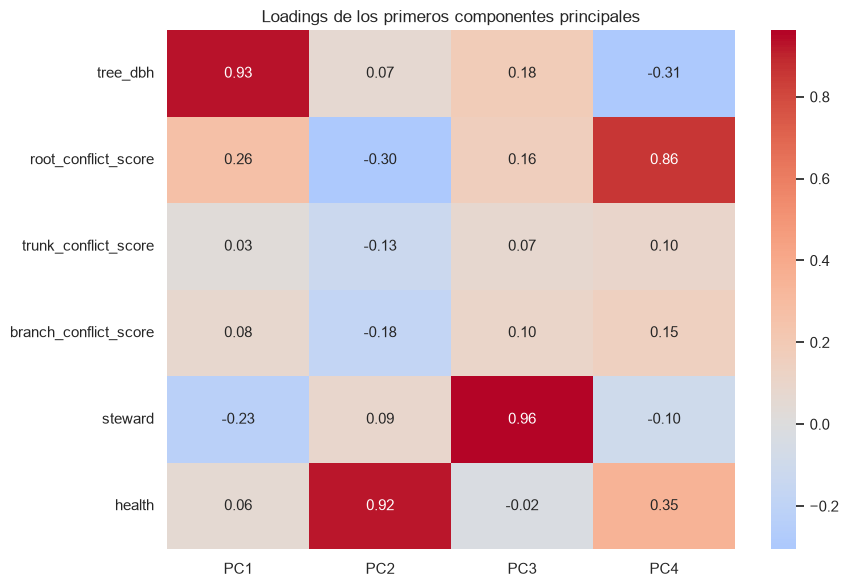

In [11]:
# Loadings: peso de cada variable original en los primeros componentes
n_show = max(3, min(n_80, 4))
loadings = pd.DataFrame(
    pca_full.components_[:n_show].T,
    index=feature_names,
    columns=[f'PC{i + 1}' for i in range(n_show)]
)
display(loadings.round(3))

plt.figure(figsize=(9, 6))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Loadings de los primeros componentes principales')
plt.tight_layout()
plt.show()

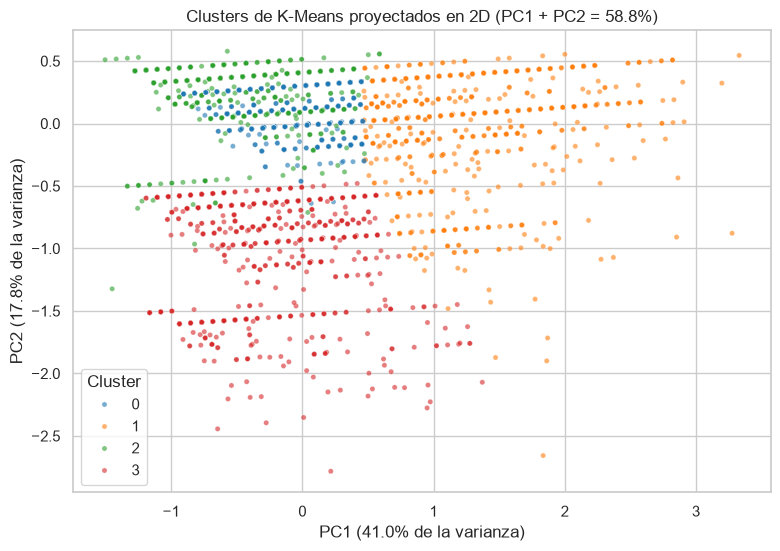

In [12]:
# Proyección 2D coloreada por los clusters de K-Means (muestra de 5000 para legibilidad)
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
Z2 = pca_2d.fit_transform(X_scaled)
plt.figure(figsize=(9, 6))
sns.scatterplot(x=Z2[idx, 0], y=Z2[idx, 1], hue=labels_km[idx], palette='tab10', s=14, alpha=0.6)
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0] * 100:.1f}% de la varianza)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1] * 100:.1f}% de la varianza)')
plt.title(f'Clusters de K-Means proyectados en 2D (PC1 + PC2 = {pca_2d.explained_variance_ratio_.sum() * 100:.1f}%)')
plt.legend(title='Cluster')
plt.show()

### Conclusiones:

1. **Hacen falta 4 de los 6 componentes para llegar al 80% de la varianza** (5 para el 90%). Casi no se comprime: pasar de 6 variables a 4 es una reducción modesta.
2. **Aplica lo que vimos para cuando se necesitan más de 3 componentes:** PC1 y PC2 juntos explican solo el **58,8%**, así que la proyección 2D es una vista **parcial** y no hay que forzar conclusiones sobre ella. La herramienta principal de este análisis es el scree plot con la varianza acumulada, y los 4 componentes retenidos serían la reducción dimensional a usar en modelos posteriores.
3. **Cada componente "es" casi una variable original** (ver loadings):
   - **PC1 = tamaño del árbol** (`tree_dbh` pesa 0,93).
   - **PC2 = salud** (`health`, 0,92).
   - **PC3 = cuidado vecinal** (`steward`, 0,96).
   - **PC4 = conflictos de raíz** (`root_conflict_score`, 0,86).
4. **Lectura:** que los componentes coincidan casi uno a uno con las variables originales significa que **están poco correlacionadas entre sí**. Cada una aporta información propia y por eso PCA no puede resumirlas en pocos ejes. Es un hallazgo en sí mismo: no hay una "dimensión oculta" que explique todo. Además, estos ejes coinciden con los que separaban a los clusters (tamaño, salud y cuidado), lo que refuerza la coherencia entre las dos técnicas.

---

## 7. DBSCAN: agrupar por densidad y detectar anomalías

### Objetivo:
**DBSCAN** agrupa por **densidad**: un grupo es una zona donde hay muchos puntos cercanos entre sí, y los puntos aislados quedan como **ruido** (etiqueta `-1`). No necesita que le digamos cuántos grupos queremos, pero sí dos parámetros:

- **`min_samples`:** cuántos vecinos hacen falta para considerar densa una zona. Usamos la regla práctica de 2 × cantidad de dimensiones (2 × 6 = 12).
- **`eps` (ε):** el radio de vecindad. Lo determinamos con el **gráfico de k-distancias**: para cada árbol, la distancia a su vecino número `min_samples`, ordenada de menor a mayor. El "codo" de esa curva sugiere el radio donde se pasa de zonas densas a puntos aislados.

Luego probamos distintos valores de ε para ver si DBSCAN logra segmentar de verdad o si colapsa. Si no segmenta, lo usaremos como **detector de anomalías**, analizando los casos de la etiqueta `-1`.


min_samples = 12
eps sugerido por el codo de la curva de k-distancias: 0.091
Percentiles de la k-distancia: {50: 0.0, 90: 0.091, 95: 0.364, 99: 1.004}


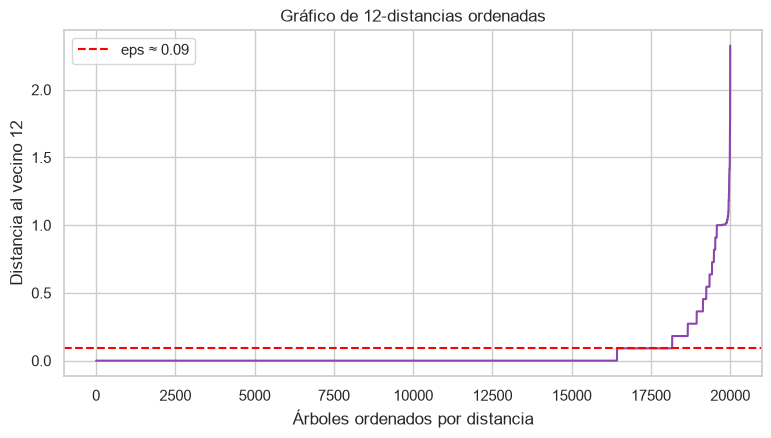

In [13]:
# 1. k-distancias: distancia de cada punto a su k-ésimo vecino, con k = min_samples
min_samples = 2 * X_scaled.shape[1]   # regla práctica: 2 x cantidad de dimensiones
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
dist, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(dist[:, -1])

# Codo de la curva: punto más alejado de la recta que une los extremos
x_ = np.arange(len(k_dist))
p1, p2 = np.array([0, k_dist[0]]), np.array([len(k_dist) - 1, k_dist[-1]])
v = p2 - p1
w = np.c_[x_, k_dist] - p1
d_line = np.abs(v[0] * w[:, 1] - v[1] * w[:, 0]) / np.linalg.norm(v)
eps_codo = float(k_dist[np.argmax(d_line)])

print(f"min_samples = {min_samples}")
print(f"eps sugerido por el codo de la curva de k-distancias: {eps_codo:.3f}")
print("Percentiles de la k-distancia:", {p: round(float(np.percentile(k_dist, p)), 3) for p in [50, 90, 95, 99]})

plt.figure(figsize=(9, 4.5))
plt.plot(k_dist, color='#8e44ad')
plt.axhline(eps_codo, color='red', linestyle='--', label=f'eps ≈ {eps_codo:.2f}')
plt.title(f'Gráfico de {min_samples}-distancias ordenadas')
plt.xlabel('Árboles ordenados por distancia')
plt.ylabel(f'Distancia al vecino {min_samples}')
plt.legend()
plt.show()

In [14]:
# 2. Sensibilidad a eps: ¿DBSCAN logra segmentar o colapsa?
filas = []
for e in [0.5, 1.0, eps_codo, 2.0, 3.0]:
    lab = DBSCAN(eps=e, min_samples=min_samples).fit_predict(X_scaled)
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    filas.append({'eps': round(e, 3), 'Clusters': n_cl, '% Ruido (-1)': round((lab == -1).mean() * 100, 2),
                  '% en el cluster mayor': round(pd.Series(lab[lab != -1]).value_counts(normalize=True).max() * 100, 2) if n_cl else 0})
display(pd.DataFrame(filas))

eps_final = round(eps_codo, 3)
dbscan = DBSCAN(eps=eps_final, min_samples=min_samples).fit(X_scaled)
labels_db = dbscan.labels_
print(f"\nDBSCAN final (eps={eps_final}, min_samples={min_samples}):")
print(pd.Series(labels_db).value_counts().sort_index().rename('Cantidad').to_frame().T.to_string())

,eps,Clusters,% Ruido (-1),% en el cluster mayor
0,0.50,53,2.54,41.10
1,1.00,1,0.30,100.00
2,0.09,44,8.07,43.54
3,2.00,1,0.00,100.00
4,3.00,1,0.00,100.00



DBSCAN final (eps=0.091, min_samples=12):
           -1    0    1     2     3     4     5    6    7    8    9    10   11   12   13   14   15   16   17   18   19   20   21   22   23   24   25   26   27   28   29   30   31   32   33   34   35   36   37   38   39   40   41   42   43
Cantidad  1614   23  418  8005  1129  2235  2563   31  133  649  328  351  387   86  131  325  414  178   67   21   74   36   68   75  138  148   20   17   61   19   24   28   17   29   17   23   12   12   23   17    9   18   13    7    7


In [15]:
# 3. Análisis cualitativo de los puntos de ruido (etiqueta -1) en unidades originales
es_ruido = labels_db == -1
print(f"Árboles marcados como ruido/anomalía: {es_ruido.sum():,} ({es_ruido.mean() * 100:.2f}%)")
if es_ruido.sum() > 0:
    comp = pd.DataFrame({
        'Ruido (-1)': X[es_ruido][features_num].mean(),
        'Resto': X[~es_ruido][features_num].mean()
    })
    display(comp.round(2))
    print("\nSalud en el ruido vs el resto (%):")
    display((pd.DataFrame({'Ruido': X[es_ruido]['health'].value_counts(normalize=True),
                           'Resto': X[~es_ruido]['health'].value_counts(normalize=True)}) * 100).round(1))
    print("\nBorough en el ruido vs el resto (%):")
    display((pd.DataFrame({'Ruido': contexto[es_ruido]['borough'].value_counts(normalize=True),
                           'Resto': contexto[~es_ruido]['borough'].value_counts(normalize=True)}) * 100).round(1))

Árboles marcados como ruido/anomalía: 1,614 (8.07%)


,Ruido (-1),Resto
tree_dbh,16.95,11.17
root_conflict_score,0.74,0.23
trunk_conflict_score,0.54,0.03
branch_conflict_score,0.59,0.10



Salud en el ruido vs el resto (%):


,Ruido,Resto
health,,
Good,49.10,83.80
Fair,29.70,13.50
Poor,21.20,2.80



Borough en el ruido vs el resto (%):


,Ruido,Resto
borough,,
Bronx,8.20,12.60
Brooklyn,32.90,25.50
Manhattan,14.10,9.10
Queens,36.70,36.80
Staten Island,8.10,16.10


### Conclusiones:

1. **Las k-distancias muestran un dato curioso:** la mediana es **0,0**. Es decir, más de la mitad de los árboles tiene al menos otros 11 árboles *idénticos* en las seis variables. Es consecuencia de que las variables son discretas (pocos valores posibles).
2. **DBSCAN no logra una segmentación limpia con ningún ε:**
   - Con el ε del codo (0,091) genera **44 grupos**, donde el mayor concentra el 40% de los árboles y el resto son fragmentos diminutos de entre 7 y 2.500 árboles. No son perfiles interpretables.
   - Con ε = 0,5 genera 53 grupos.
   - Con **ε ≥ 1 todo colapsa en un único grupo**.
3. **Aplica la salida de "datos unimodales/discretos":** como lo indica el criterio para estos casos, no forzamos la partición por densidad y **usamos DBSCAN como detector de anomalías**. Dejamos K-Means como agrupamiento principal.
4. **Perfil de las anomalías (ruido = 1.614 árboles, el 8,1%):** comparadas con el resto, son claramente distintas:

| Variable | Anomalías (-1) | Resto |
|---|:---:|:---:|
| Diámetro promedio (pulg) | **17,0** | 11,2 |
| Conflicto de raíz | **0,74** | 0,23 |
| Conflicto de tronco | **0,54** | 0,03 |
| Conflicto de ramas | **0,59** | 0,10 |
| % salud buena | **49%** | 84% |
| % salud mala | **21%** | 2,8% |

   Son árboles **grandes, enfermos y con muchos problemas a la vez** (especialmente en el tronco, que tiene 18 veces más conflictos). Casi todos los demás árboles tienen un solo tipo de problema o ninguno; estos los acumulan. La distribución por barrio es bastante parecida a la del resto (algo más de Brooklyn y menos de Staten Island), así que no es un fenómeno geográfico.

---

## 8. Validación externa: ¿coinciden los grupos con el daño en la vereda?

### Objetivo:
Recién ahora **reincorporamos la etiqueta `sidewalk`**, que mantuvimos apartada todo el tiempo, y la usamos únicamente como **validación externa**: comparamos los grupos que descubrió el algoritmo (sin saber nada del daño) con las clases reales (con daño / sin daño). Lo hacemos con:

- **Una matriz cruzada** (`pd.crosstab`), para ver qué porcentaje de cada cluster tiene la vereda dañada.
- **El *Adjusted Rand Index* (ARI)**, que mide cuánto coinciden dos particiones: 0 significa azar y 1 coincidencia perfecta.

Es importante tener claro qué esperar: **los clusters no se construyeron para predecir el daño**, así que no hay motivo para que coincidan. Esta comparación sirve para saber si la estructura natural de los datos tiene relación con el problema original.


In [16]:
# 1. Matriz cruzada: cluster de K-Means vs etiqueta real (solo ahora reincorporamos 'sidewalk')
tabla = pd.crosstab(labels_km, y_externa.map({0: 'Sin Daño', 1: 'Con Daño'}), rownames=['Cluster'])
tabla['% Con Daño'] = tabla['Con Daño'] / tabla.sum(axis=1) * 100
display(tabla.round(1))
print(f"Tasa de daño general de la muestra: {y_externa.mean() * 100:.1f}%")

# 2. Adjusted Rand Index: 0 = azar, 1 = coincidencia perfecta
ari_km = adjusted_rand_score(y_externa, labels_km)
print(f"\nARI K-Means (K={K_ELEGIDO}) vs sidewalk real: {ari_km:.4f}")

# 3. Lo mismo para DBSCAN, sobre los puntos que no son ruido
mask = labels_db != -1
if len(set(labels_db[mask])) > 1:
    print(f"ARI DBSCAN vs sidewalk real (sin ruido): {adjusted_rand_score(y_externa[mask], labels_db[mask]):.4f}")
else:
    print("DBSCAN generó un único cluster (más ruido): el ARI no es informativo.")

# 4. ARI contra una partición binaria de K-Means (K=2) como referencia comparable
labels_k2 = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
print(f"ARI K-Means (K=2) vs sidewalk real: {adjusted_rand_score(y_externa, labels_k2):.4f}")

sidewalk,Con Daño,Sin Daño,% Con Daño
Cluster,,,
0,1865,6535,22.20
1,2123,2464,46.30
2,816,2982,21.50
3,828,2387,25.80


Tasa de daño general de la muestra: 28.2%

ARI K-Means (K=4) vs sidewalk real: 0.0316
ARI DBSCAN vs sidewalk real (sin ruido): 0.0657
ARI K-Means (K=2) vs sidewalk real: 0.1107


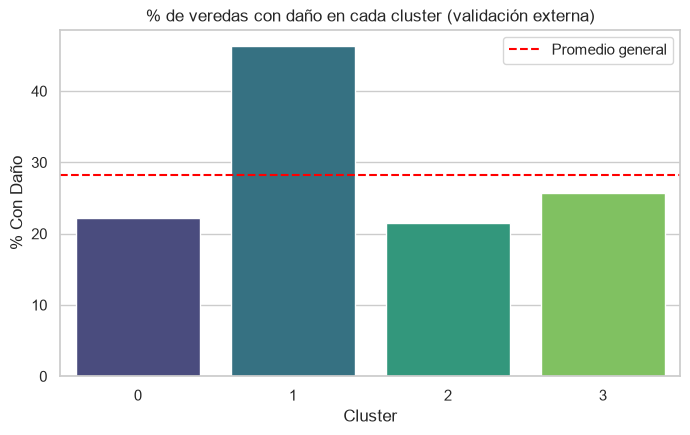

In [17]:
plt.figure(figsize=(8, 4.5))
tasa = tabla['% Con Daño']
sns.barplot(x=tasa.index, y=tasa.values, palette='viridis')
plt.axhline(y_externa.mean() * 100, color='red', linestyle='--', label='Promedio general')
plt.title('% de veredas con daño en cada cluster (validación externa)')
plt.xlabel('Cluster')
plt.ylabel('% Con Daño')
plt.legend()
plt.show()

### Conclusiones:

1. **Un cluster se destaca claramente:** el de **árboles grandes y maduros (cluster 1)** tiene **46,3% de veredas dañadas**, frente al 28,2% general (1,6 veces más). Los otros tres están por debajo o cerca del promedio (22,2%, 21,5% y 25,8%).
2. **Coincide con lo que encontró el modelo supervisado:** en la Parte 1 las variables más importantes para predecir el daño eran justamente el **diámetro del tronco** y los **conflictos de raíz**. Acá, sin usar la etiqueta, el algoritmo aisló por su cuenta al grupo con árboles grandes y más conflictos de raíz, y resultó ser el de más daño. Dos enfoques distintos llegan a la misma conclusión.
3. **El ARI es bajo:** 0,032 para K-Means (K=4) y 0,111 para K=2. Valores cercanos a 0 indican que **la partición en grupos no replica la división con/sin daño**. El de DBSCAN (0,066) no es informativo porque fragmentó en 44 grupos.
4. **Esto no es un fracaso:** que los grupos no coincidan con el daño es esperable. Los clusters ordenan a los árboles por **tipo** (tamaño, cuidado, salud), mientras que el daño depende además de factores que el censo no tiene (el material de la vereda, su antigüedad). Los clusters ayudan a **entender** el arbolado, no a **predecir** el daño: para eso sirve el modelo supervisado.

---

## 9. Conclusiones finales de la Parte 2

### 1. Qué hicimos y qué encontramos

| Técnica | Resultado principal |
|---|---|
| **K-Means (K=4)** | Cuatro perfiles interpretables: jóvenes sanos sin cuidado (42%), árboles grandes y maduros (23%), jóvenes cuidados por vecinos (19%) y árboles con mala salud (16%). Silhouette = 0,33 (estructura moderada). |
| **PCA** | Hacen falta 4 de 6 componentes para el 80% de la varianza: casi no se comprime. Los ejes son tamaño, salud, cuidado vecinal y conflictos de raíz. |
| **DBSCAN** | No segmenta (fragmenta con ε chico y colapsa con ε grande). Funciona bien como **detector de anomalías**: 8% de árboles grandes, enfermos y con muchos conflictos. |
| **Validación externa** | El cluster de árboles grandes tiene 46% de veredas dañadas (vs. 28% general). ARI bajo: los grupos no replican el daño. |

### 2. Cómo se aplicaron las salidas previstas para los casos particulares
- **Dataset con target (Escenario A):** retiramos `sidewalk` del agrupamiento y lo reincorporamos solo al final, con `crosstab` y ARI.
- **DBSCAN no segmenta (Escenario B):** no forzamos la partición por densidad; lo usamos para analizar los casos de ruido (`-1`) y mantuvimos K-Means como agrupamiento principal.
- **PCA necesita más de 3 componentes (Escenario C):** reportamos el scree plot con la varianza acumulada y señalamos los 4 componentes para el 80% como reducción analítica, sin sobreinterpretar el gráfico 2D (que explica solo el 58,8%).

### 3. Supervisado vs. no supervisado: qué nos dio cada uno

| | Parte 1 (supervisado) | Parte 2 (no supervisado) |
|---|---|---|
| **Respuesta** | Predice si una vereda estará dañada (F1 ≈ 0,54, Recall 61%) | Describe tipos de árboles y detecta casos atípicos |
| **Utilidad para la ciudad** | Priorizar inspecciones con una lista de árboles de riesgo | Entender la composición del arbolado y focalizar en perfiles (ej. árboles grandes con conflictos de raíz) |
| **Hallazgo en común** | Tamaño del tronco y conflictos de raíz son los factores clave | El grupo de árboles grandes y con más conflicto de raíz es el de mayor daño |

Las dos partes **se complementan:** el supervisado dice *cuáles* son los árboles de riesgo y el no supervisado ayuda a entender *qué tipo de árbol* es cada uno.

### 4. Limitaciones honestas de nuestro trabajo
- **El resultado depende de las variables elegidas:** al incluir `borough` con One-Hot los grupos se armaban por barrio. Decidir qué variables entran al agrupamiento condiciona todo lo que se descubre.
- **El Silhouette está inflado por las variables discretas:** al haber pocos valores posibles, muchos árboles son idénticos y el indicador sube con *K* sin que haya estructura nueva. Por eso elegimos *K* también por interpretabilidad.
- **Estructura moderada:** un Silhouette de 0,33 indica grupos reales pero con bordes difusos.
- **Trabajamos con una muestra de 20.000 árboles** (el 3% del total) por costo computacional. Los resultados deberían ser estables, pero no los verificamos con otras muestras.
- **Asociación no es causalidad:** que los árboles grandes tengan más daño no demuestra que sean la causa. Puede reflejar que están en zonas con veredas antiguas.
- **PCA no pudo comprimir:** las variables son poco correlacionadas, así que no hay una reducción dimensional significativa.
